<a href="https://colab.research.google.com/github/pg130907/Cross-Lingual/blob/main/week1_data_preprocessingf.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Week 1: Data Collection and Preprocessing

## Objective
Build a preprocessing pipeline for Indian-language text
and establish a baseline for multilingual intent classification.

## Dataset
Amazon MASSIVE (Hindi subset)

## Tasks
1. Load and explore the dataset.
2. Analyze intent labels and text distribution.
3. Clean and normalize text.
4. Train a baseline classifier.
5. Evaluate performance.
6. Document results and limitations.


In [1]:

!pip install -q datasets transformers sentencepiece scikit-learn pandas matplotlib


In [2]:

import re
import json
import random
import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from datasets import load_dataset

random.seed(42)
np.random.seed(42)

print("Environment ready!")


Environment ready!



## 1. Dataset Acquisition

We use the Amazon MASSIVE dataset, which provides
multilingual utterances annotated with intent labels.

Hindi is selected for the initial implementation.

The dataset includes predefined training, validation,
and test splits. The test split will be reserved for
final evaluation.


In [4]:


from datasets import load_dataset

# Load the Hindi MASSIVE Parquet files directly.
# This bypasses the unsupported massive.py script.

base_url = (
    "https://huggingface.co/datasets/"
    "AmazonScience/massive/resolve/"
    "refs%2Fconvert%2Fparquet/hi-IN"
)

data_files = {
    "train": f"{base_url}/train/0000.parquet",
    "validation": f"{base_url}/validation/0000.parquet",
    "test": f"{base_url}/test/0000.parquet"
}

dataset = load_dataset(
    "parquet",
    data_files=data_files
)

print(dataset)
print("\nFirst training example:")
print(dataset["train"][0])

print(dataset)
print("\nFirst example:")
print(dataset["train"][0])


hi-IN/train/0000.parquet: reconstructing file:   0%|          |  0.00B / 1.10MB            

hi-IN/train/0000.parquet: downloading bytes:           |  0.00B            

0000.parquet:   0%|          | 0.00/215k [00:00<?, ?B/s]

0000.parquet:   0%|          | 0.00/299k [00:00<?, ?B/s]

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'locale', 'partition', 'scenario', 'intent', 'utt', 'annot_utt', 'worker_id', 'slot_method', 'judgments'],
        num_rows: 11514
    })
    validation: Dataset({
        features: ['id', 'locale', 'partition', 'scenario', 'intent', 'utt', 'annot_utt', 'worker_id', 'slot_method', 'judgments'],
        num_rows: 2033
    })
    test: Dataset({
        features: ['id', 'locale', 'partition', 'scenario', 'intent', 'utt', 'annot_utt', 'worker_id', 'slot_method', 'judgments'],
        num_rows: 2974
    })
})

First training example:
{'id': '1', 'locale': 'hi-IN', 'partition': 'train', 'scenario': 16, 'intent': 48, 'utt': 'शुक्रवार को सुबह नौ बजे मुझे जगा दो', 'annot_utt': '[date : शुक्रवार] को सुबह [time : नौ बजे] मुझे जगा दो', 'worker_id': '45', 'slot_method': {'slot': ['time', 'date'], 'method': ['translation', 'translation']}, 'judgments': {'worker_id': ['16', '3', '42'], 'intent_score': [1, 1, 1], 'slots_score': [1, 1, 1], 'g

In [5]:

print("Training samples:", len(dataset["train"]))
print("Validation samples:", len(dataset["validation"]))
print("Test samples:", len(dataset["test"]))

print("\nColumns:", dataset["train"].column_names)
print("\nFeatures:", dataset["train"].features)

import pandas as pd

df = dataset["train"].to_pandas()
display(df[["utt", "intent"]].head(10))


Training samples: 11514
Validation samples: 2033
Test samples: 2974

Columns: ['id', 'locale', 'partition', 'scenario', 'intent', 'utt', 'annot_utt', 'worker_id', 'slot_method', 'judgments']

Features: {'id': Value('string'), 'locale': Value('string'), 'partition': Value('string'), 'scenario': ClassLabel(names=['social', 'transport', 'calendar', 'play', 'news', 'datetime', 'recommendation', 'email', 'iot', 'general', 'audio', 'lists', 'qa', 'cooking', 'takeaway', 'music', 'alarm', 'weather']), 'intent': ClassLabel(names=['datetime_query', 'iot_hue_lightchange', 'transport_ticket', 'takeaway_query', 'qa_stock', 'general_greet', 'recommendation_events', 'music_dislikeness', 'iot_wemo_off', 'cooking_recipe', 'qa_currency', 'transport_traffic', 'general_quirky', 'weather_query', 'audio_volume_up', 'email_addcontact', 'takeaway_order', 'email_querycontact', 'iot_hue_lightup', 'recommendation_locations', 'play_audiobook', 'lists_createoradd', 'news_query', 'alarm_query', 'iot_wemo_on', 'gene

,utt,intent
0,शुक्रवार को सुबह नौ बजे मुझे जगा दो,48
1,अभी से दो घंटे के लिए अलार्म लगाओ,48
2,olly चुप रहो,46
3,रुको,46
4,olly दस सेकंड के लिए रुको,46
5,दस सेकंड के लिए रुकें,46
6,यहां रोशनी को थोड़ा अधिक गर्म करें,1
7,लाइट को पढ़ने के लिए उपयुक्त होने तक सेट करें,1
8,सोने का समय,40
9,सोने का समय olly,40


In [6]:

intent_feature = dataset["train"].features["intent"]

if hasattr(intent_feature, "names"):
    intent_names = intent_feature.names
    label_to_name = lambda x: intent_names[int(x)]
else:
    label_to_name = lambda x: str(x)

train_df = dataset["train"].to_pandas()
train_df["intent_name"] = train_df["intent"].apply(label_to_name)

display(train_df[["utt", "intent_name"]].head(10))


,utt,intent_name
0,शुक्रवार को सुबह नौ बजे मुझे जगा दो,alarm_set
1,अभी से दो घंटे के लिए अलार्म लगाओ,alarm_set
2,olly चुप रहो,audio_volume_mute
3,रुको,audio_volume_mute
4,olly दस सेकंड के लिए रुको,audio_volume_mute
5,दस सेकंड के लिए रुकें,audio_volume_mute
6,यहां रोशनी को थोड़ा अधिक गर्म करें,iot_hue_lightchange
7,लाइट को पढ़ने के लिए उपयुक्त होने तक सेट करें,iot_hue_lightchange
8,सोने का समय,iot_hue_lightoff
9,सोने का समय olly,iot_hue_lightoff



## Exploring AI4Bharat IndicCorpV2

IndicCorpV2 is a large monolingual corpus containing
Indian-language text.

We inspect a small sample to understand its structure,
script characteristics, and preprocessing requirements.

Since the corpus does not contain intent labels,
it will not be used to train the supervised
intent-classification baseline.


In [8]:

from datasets import load_dataset

indic_data = load_dataset(
    "ai4bharat/IndicCorpV2",
    "indiccorp_v2",
    split="hin_Deva",
    streaming=True
)

# Read only 10 Hindi text samples
samples = list(indic_data.take(10))

for i, sample in enumerate(samples, 1):
    print(f"\nSample {i}:")
    print(sample["text"][:500])




Sample 1:
लोगों को बिलों संबंधी सुविधा देना ही उनका काम

Sample 2:


Sample 3:
इनेलो 1987 में उस वक्त ऐसे ही दोराहे पर खड़ी थी, जब पूर्व उपप्रधानमंत्री देवीलाल ने अपने पुत्र ओमप्रकाश चौटाला को अपना राजनीतिक उत्तराधिकारी घोषित किया था। हालांकि तब पार्टी पर देवीलाल की मजबूत पकड़ के चलते पार्टी टूटने से बच गई थी। 1989 में देवीलाल केन्द्र की राजनीति में सक्रिय हो गए थे और उनके उपप्रधानमंत्री बनने के पश्चात् उनके तीन बेटों जगदीश सिंह, रणजीत सिंह और ओमप्रकाश चौटाला में से रणजीत और ओमप्रकाश के बीच हरियाणा में उनकी राजनीतिक विरासत को लेकर जंग शुरू हो गई थी। उन परिस्थितियों में देव

Sample 4:


Sample 5:
जहां आई थी तबाही उस घाटी क्षेत्र में खतरा ज्यादा

Sample 6:


Sample 7:
इसके बाद केंद्र की ओर से प्रदेश सरकार को पीएमजीएसवाई में 200 करोड़ रुपये की राशि उपलब्ध करा दी गई। भाजपा के मीडिया प्रभारी दिवाकर सिंह ने शनिवार को बताया कि केंद्र ने प्रदेश सरकार को 200 करोड़ रुपये भेजा है।

Sample 8:


Sample 9:
यह पूछने पर कि इस बड़े मैच से पहले उनकी नींद गायब हुई तो बाबर ने कहा, "हम काफी टूर्नामेंट खेल

In [10]:

import re
import unicodedata
import pandas as pd

def clean_text(text):
    # Normalize Unicode characters
    text = unicodedata.normalize("NFC", text)

    # Replace URLs
    text = re.sub(
        r"https?://\S+|www\.\S+",
        " URL ",
        text
    )

    # Remove extra whitespace
    text = re.sub(r"\s+", " ", text)

    return text.strip()

print("Text cleaning function is ready!")


Text cleaning function is ready!


In [11]:

import pandas as pd

comparison = pd.DataFrame({
    "original": [x["text"] for x in samples],
    "cleaned": [clean_text(x["text"]) for x in samples]
})

display(comparison)


,original,cleaned
0,लोगों को बिलों संबंधी सुविधा देना ही उनका काम,लोगों को बिलों संबंधी सुविधा देना ही उनका काम
1,,
2,इनेलो 1987 में उस वक्त ऐसे ही दोराहे पर खड़ी थ...,इनेलो 1987 में उस वक्त ऐसे ही दोराहे पर खड़ी थ...
3,,
4,जहां आई थी तबाही उस घाटी क्षेत्र में खतरा ज्यादा,जहां आई थी तबाही उस घाटी क्षेत्र में खतरा ज्यादा
5,,
6,इसके बाद केंद्र की ओर से प्रदेश सरकार को पीएमज...,इसके बाद केंद्र की ओर से प्रदेश सरकार को पीएमज...
7,,
8,यह पूछने पर कि इस बड़े मैच से पहले उनकी नींद ग...,यह पूछने पर कि इस बड़े मैच से पहले उनकी नींद ग...
9,,


In [12]:

comparison["changed"] = (
    comparison["original"] != comparison["cleaned"]
)

print("Total samples:", len(comparison))
print("Samples changed:", comparison["changed"].sum())

display(comparison)


Total samples: 10
Samples changed: 0


,original,cleaned,changed
0,लोगों को बिलों संबंधी सुविधा देना ही उनका काम,लोगों को बिलों संबंधी सुविधा देना ही उनका काम,False
1,,,False
2,इनेलो 1987 में उस वक्त ऐसे ही दोराहे पर खड़ी थ...,इनेलो 1987 में उस वक्त ऐसे ही दोराहे पर खड़ी थ...,False
3,,,False
4,जहां आई थी तबाही उस घाटी क्षेत्र में खतरा ज्यादा,जहां आई थी तबाही उस घाटी क्षेत्र में खतरा ज्यादा,False
5,,,False
6,इसके बाद केंद्र की ओर से प्रदेश सरकार को पीएमज...,इसके बाद केंद्र की ओर से प्रदेश सरकार को पीएमज...,False
7,,,False
8,यह पूछने पर कि इस बड़े मैच से पहले उनकी नींद ग...,यह पूछने पर कि इस बड़े मैच से पहले उनकी नींद ग...,False
9,,,False


In [13]:

# Inspect 1000 samples from IndicCorpV2
raw_samples = list(indic_data.take(1000))

raw_texts = [
    sample.get("text") or ""
    for sample in raw_samples
]

# Detect empty or whitespace-only lines
empty_count = sum(
    not text.strip() for text in raw_texts
)

print("Total raw samples:", len(raw_texts))
print("Empty samples:", empty_count)
print("Non-empty samples:", len(raw_texts) - empty_count)


Total raw samples: 1000
Empty samples: 500
Non-empty samples: 500


In [14]:

# Remove empty lines
valid_texts = [
    text for text in raw_texts
    if text.strip()
]

# Apply existing cleaning function
cleaned_texts = [
    clean_text(text)
    for text in valid_texts
]

comparison = pd.DataFrame({
    "original": valid_texts,
    "cleaned": cleaned_texts
})

comparison["changed"] = (
    comparison["original"] != comparison["cleaned"]
)

print("Valid samples:", len(comparison))
print("Changed samples:", comparison["changed"].sum())
print("Duplicate cleaned samples:",
      comparison["cleaned"].duplicated().sum())

display(comparison.head(10))


Valid samples: 500
Changed samples: 104
Duplicate cleaned samples: 0


,original,cleaned,changed
0,लोगों को बिलों संबंधी सुविधा देना ही उनका काम,लोगों को बिलों संबंधी सुविधा देना ही उनका काम,False
1,इनेलो 1987 में उस वक्त ऐसे ही दोराहे पर खड़ी थ...,इनेलो 1987 में उस वक्त ऐसे ही दोराहे पर खड़ी थ...,False
2,जहां आई थी तबाही उस घाटी क्षेत्र में खतरा ज्यादा,जहां आई थी तबाही उस घाटी क्षेत्र में खतरा ज्यादा,False
3,इसके बाद केंद्र की ओर से प्रदेश सरकार को पीएमज...,इसके बाद केंद्र की ओर से प्रदेश सरकार को पीएमज...,False
4,यह पूछने पर कि इस बड़े मैच से पहले उनकी नींद ग...,यह पूछने पर कि इस बड़े मैच से पहले उनकी नींद ग...,False
5,"समाचार एजेंसी 'डीपीए' के अनुसार, उप गृह मंत्री...","समाचार एजेंसी 'डीपीए' के अनुसार, उप गृह मंत्री...",False
6,प्रियंका माहेश्वरी ने किया है एमबीए,प्रियंका माहेश्वरी ने किया है एमबीए,False
7,बुधवार सुबह 10.30 बजे बड़ी संख्या में एबीवीपी क...,बुधवार सुबह 10.30 बजे बड़ी संख्या में एबीवीपी ...,True
8,बता दें कि ये फोटो ड्रग्स पैडलर द्वारा सैंपल क...,बता दें कि ये फोटो ड्रग्स पैडलर द्वारा सैंपल क...,False
9,विक्टोरिया: प्रधानमंत्री नरेंद्र मोदी ने आज कह...,विक्टोरिया: प्रधानमंत्री नरेंद्र मोदी ने आज कह...,False


count      500.000000
mean       315.060000
std        599.523224
min         11.000000
25%         79.000000
50%        227.000000
75%        368.750000
max      10684.000000
Name: length, dtype: float64


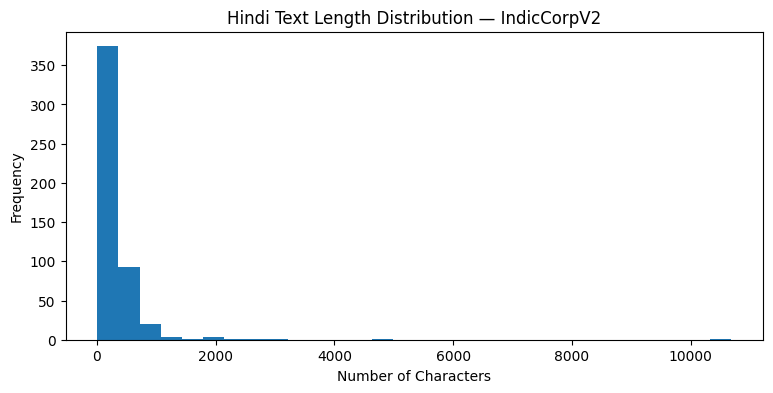

In [15]:

comparison["length"] = comparison["cleaned"].str.len()

print(comparison["length"].describe())

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 4))
plt.hist(comparison["length"], bins=30)
plt.title("Hindi Text Length Distribution — IndicCorpV2")
plt.xlabel("Number of Characters")
plt.ylabel("Frequency")
plt.show()


In [16]:

from datasets import load_dataset

samanantar = load_dataset(
    "parquet",
    data_files=(
        "hf://datasets/ai4bharat/samanantar/"
        "hi/train-00000-of-00008.parquet"
    ),
    split="train",
    streaming=True
)

parallel_samples = list(samanantar.take(20))
parallel_df = pd.DataFrame(parallel_samples)

display(parallel_df[["src", "tgt"]].head(10))


,src,tgt
0,"However, Paes, who was partnering Australia's ...",आस्ट्रेलिया के पाल हेनली के साथ जोड़ी बनाने वाल...
1,"Whosoever desires the reward of the world, wit...",और जो शख्स (अपने आमाल का) बदला दुनिया ही में च...
2,The value of insects in the biosphere is enorm...,"जैव-मंडल में कीड़ों का मूल्य बहुत है, क्योंकि ..."
3,Mithali To Anchor Indian Team Against Australi...,आस्ट्रेलिया के खिलाफ वनडे टीम की कमान मिताली को
4,After the assent of the Honble President on 8t...,"8 सितम्‍बर, 2016 को माननीय राष्‍ट्रपति की स्‍व..."
5,The court has fixed a hearing for February 12,अदालत ने इस मामले में आगे की सुनवाई के लिए एक ...
6,Please select the position where the track sho...,"जहाँ पर ट्रैक को विभाजित किया जाना है, कृपया व..."
7,"As per police, armys 22RR, special operation G...",इसके तुरंत बाद सेना की 22 राष्ट्रीय राइफल्स (आ...
8,Jharkhand chief minister Hemant Soren,झारखंड के मुख्यमंत्री हेमंत सोरेन (फोटोः पीटीआई)
9,"Arvind Kumar, SHO of the sector 55/56 police s...",सेक्टर 55/56 के एसएचओ अरविंद कुमार ने बताया कि...


In [17]:

sentiment = load_dataset(
    "json",
    data_files={
        "validation": (
            "hf://datasets/ai4bharat/IndicSentiment/"
            "data/validation/hi.json"
        )
    },
    split="validation"
)

sentiment_df = sentiment.to_pandas()

display(sentiment_df[
    ["INDIC REVIEW", "LABEL"]
].head())

print(sentiment_df["LABEL"].value_counts())


hi.json:   0%|          | 0.00/178k [00:00<?, ?B/s]

Generating validation split: 0 examples [00:00, ? examples/s]

,INDIC REVIEW,LABEL
0,बोट के साउंडबार में अभी भी सभी स्पीकर्स के लिए...,Negative
1,माइक और माइक्रो एसडी कार्ड स्लॉट के साथ फोल्डे...,Positive
2,हाल ही में डाला गया फीचर जो डिफ़ॉल्ट रूप से 24...,Positive
3,"""रेट्स प्रतिस्पर्धी हैं, लगभग मार्किट में सबसे...",Positive
4,बहुत बड़ा और बेहतरीन दिखता है। लेकिन चूंकि कोई...,Negative


LABEL
Negative    81
Positive    75
Name: count, dtype: int64


In [18]:

def clean_noisy_text(text):
    text = unicodedata.normalize("NFC", text)

    text = re.sub(
        r"https?://\S+|www\.\S+",
        " URL ",
        text
    )

    text = re.sub(
        r"(?<!\w)@[\w.]+",
        " USER ",
        text
    )

    # Retain hashtag content
    text = re.sub(r"(?<!\w)#(\w+)", r"\1", text)

    text = re.sub(r"\s+", " ", text)

    return text.strip()


examples = [
    "मुझे   यह अच्छा लगा 😊",
    "बहुत खराब service 😡",
    "#Amazing product मिला!",
    "@someone ये देखो https://example.com",
    "Mera order cancel kar do"
]

for example in examples:
    print("Before:", example)
    print("After: ", clean_noisy_text(example))
    print()


Before: मुझे   यह अच्छा लगा 😊
After:  मुझे यह अच्छा लगा 😊

Before: बहुत खराब service 😡
After:  बहुत खराब service 😡

Before: #Amazing product मिला!
After:  Amazing product मिला!

Before: @someone ये देखो https://example.com
After:  USER ये देखो URL

Before: Mera order cancel kar do
After:  Mera order cancel kar do



In [19]:

from transformers import AutoTokenizer
from torch.utils.data import DataLoader, TensorDataset
import torch

model_name = "ai4bharat/IndicBERTv2-MLM-only"

tokenizer = AutoTokenizer.from_pretrained(model_name)

# Use real MASSIVE examples
texts = [
    clean_noisy_text(text)
    for text in dataset["train"]["utt"][:16]
]

encoded = tokenizer(
    texts,
    padding=True,
    truncation=True,
    max_length=128,
    return_tensors="pt"
)

print("Token IDs shape:", encoded["input_ids"].shape)
print("First sentence tokens:")
print(tokenizer.convert_ids_to_tokens(
    encoded["input_ids"][0]
))

tensor_data = TensorDataset(
    encoded["input_ids"],
    encoded["attention_mask"]
)

loader = DataLoader(
    tensor_data,
    batch_size=4,
    shuffle=False
)

for input_ids, attention_mask in loader:
    print("Batch:", input_ids.shape)


config.json:   0%|          | 0.00/639 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/51.0 [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 7.75MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

Token IDs shape: torch.Size([16, 12])
First sentence tokens:
['[CLS]', 'शुक्रवार', 'को', 'सुबह', 'नौ', 'बजे', 'मुझे', 'जगा', 'दो', '[SEP]', '[PAD]', '[PAD]']
Batch: torch.Size([4, 12])
Batch: torch.Size([4, 12])
Batch: torch.Size([4, 12])
Batch: torch.Size([4, 12])


In [20]:

def preprocess_batch(batch):
    return {
        "clean_text": [
            clean_noisy_text(text)
            for text in batch["utt"]
        ]
    }

processed_massive = dataset.map(
    preprocess_batch,
    batched=True
)

print(processed_massive)

display(
    processed_massive["train"]
    .to_pandas()[["utt", "clean_text"]]
    .head(10)
)


Map:   0%|          | 0/11514 [00:00<?, ? examples/s]

Map:   0%|          | 0/2033 [00:00<?, ? examples/s]

Map:   0%|          | 0/2974 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'locale', 'partition', 'scenario', 'intent', 'utt', 'annot_utt', 'worker_id', 'slot_method', 'judgments', 'clean_text'],
        num_rows: 11514
    })
    validation: Dataset({
        features: ['id', 'locale', 'partition', 'scenario', 'intent', 'utt', 'annot_utt', 'worker_id', 'slot_method', 'judgments', 'clean_text'],
        num_rows: 2033
    })
    test: Dataset({
        features: ['id', 'locale', 'partition', 'scenario', 'intent', 'utt', 'annot_utt', 'worker_id', 'slot_method', 'judgments', 'clean_text'],
        num_rows: 2974
    })
})


,utt,clean_text
0,शुक्रवार को सुबह नौ बजे मुझे जगा दो,शुक्रवार को सुबह नौ बजे मुझे जगा दो
1,अभी से दो घंटे के लिए अलार्म लगाओ,अभी से दो घंटे के लिए अलार्म लगाओ
2,olly चुप रहो,olly चुप रहो
3,रुको,रुको
4,olly दस सेकंड के लिए रुको,olly दस सेकंड के लिए रुको
5,दस सेकंड के लिए रुकें,दस सेकंड के लिए रुकें
6,यहां रोशनी को थोड़ा अधिक गर्म करें,यहां रोशनी को थोड़ा अधिक गर्म करें
7,लाइट को पढ़ने के लिए उपयुक्त होने तक सेट करें,लाइट को पढ़ने के लिए उपयुक्त होने तक सेट करें
8,सोने का समय,सोने का समय
9,सोने का समय olly,सोने का समय olly
